# Notebook 4: PPO Reinforcement Learning Agent
## CPU-Aware RL Portfolio Optimization 

This notebook implements the CPU-aware PPO reinforcement learning agent
as specified in Chapter 3 (Methodology).

Architecture:
- Algorithm: Proximal Policy Optimization (PPO) - Schulman et al. (2017)
- State space: [CPU_t, r_PBW_t, r_BGRN_t, r_XLE_t, r_SPY_t, w_{t-1}]
- Action space: continuous portfolio weights (long-only simplex)
- Primary reward: Sortino ratio (downside-aware)
- Robustness reward: Sharpe ratio
- Training: Dec 2018 - Dec 2020 (~25 months)
- Seeds: 10 independent runs (robustness procedure)
- Test: Jan 2021 - Dec 2024 (~48 months)

In [19]:
# ============================================================
# IMPORTS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
import torch

# Load data
master = pd.read_csv("../Data/master_data.csv", index_col=0, parse_dates=True)
train  = pd.read_csv("../Data/train_data.csv",  index_col=0, parse_dates=True)
test   = pd.read_csv("../Data/test_data.csv",   index_col=0, parse_dates=True)

ASSETS     = ["PBW", "BGRN", "XLE", "SPY"]
N_ASSETS   = len(ASSETS)
N_SEEDS    = 10       # number of independent training runs
TRAIN_END  = "2020-12-31"
TEST_START = "2021-01-01"
WINDOW     = 24       # rolling window for Sortino/Sharpe calculation

print("Libraries loaded successfully.")
print(f"PyTorch version: {torch.__version__}")
print(f"Training period: {train.index[0].date()} to {train.index[-1].date()}")
print(f"Test period:     {test.index[0].date()} to {test.index[-1].date()}")
print(f"Number of seeds: {N_SEEDS}")

Libraries loaded successfully.
PyTorch version: 2.13.0
Training period: 2018-12-31 to 2020-12-31
Test period:     2021-01-31 to 2024-12-31
Number of seeds: 10


## 1. Portfolio Environment

We build a custom Gymnasium environment that simulates monthly portfolio
rebalancing. The agent observes the state, outputs weights, receives
a reward, and transitions to the next month.

State space (9 dimensions):
- CPU_t: climate policy uncertainty index (normalized)
- r_PBW_t, r_BGRN_t, r_XLE_t, r_SPY_t: monthly returns (normalized)
- w_PBW_{t-1}, w_BGRN_{t-1}, w_XLE_{t-1}, w_SPY_{t-1}: previous weights

Action space:
- 4 continuous values passed through softmax → portfolio weights
- Long-only, sum to 1

Normalization:
- All state variables normalized using TRAINING period statistics only
- Applied unchanged to test period (no look-ahead bias)

In [20]:
# ============================================================
# CUSTOM PORTFOLIO ENVIRONMENT
# ============================================================

class PortfolioEnv(gym.Env):
    """
    Custom Gymnasium environment for monthly portfolio allocation.
    
    Implements the MDP framework from Section 3.2 of the Methodology:
    - State: [CPU, asset returns, previous weights]
    - Action: portfolio weights (softmax output)
    - Reward: Sortino ratio (primary) or Sharpe ratio (robustness)
    """
    
    def __init__(self, data, reward_type="sortino", 
                 norm_mean=None, norm_std=None):
        super(PortfolioEnv, self).__init__()
        
        self.data        = data.reset_index(drop=True)
        self.reward_type = reward_type
        self.n_assets    = N_ASSETS
        self.assets      = ASSETS
        
        # State variables: CPU + 4 returns + 4 previous weights = 9
        self.n_state = 1 + N_ASSETS + N_ASSETS
        
        # Observation space: normalized continuous values
        self.observation_space = spaces.Box(
            low=-10, high=10,
            shape=(self.n_state,),
            dtype=np.float32
        )
        
        # Action space: raw scores before softmax (unbounded)
        self.action_space = spaces.Box(
            low=-3, high=3,
            shape=(self.n_assets,),
            dtype=np.float32
        )
        
        # Normalization parameters (training set statistics)
        # These are set externally to prevent look-ahead bias
        self.norm_mean = norm_mean
        self.norm_std  = norm_std
        
        # Return history for Sortino/Sharpe calculation
        self.return_history = []
        
    def _normalize(self, state_raw):
        """Normalize state using training set statistics."""
        if self.norm_mean is not None and self.norm_std is not None:
            state_norm = (state_raw - self.norm_mean) / (self.norm_std + 1e-8)
        else:
            state_norm = state_raw
        return state_norm.astype(np.float32)
    
    def _get_state(self):
        """Build the state vector at current timestep."""
        row = self.data.iloc[self.t]
        
        # CPU level + asset returns
        cpu      = row["CPU"]
        returns  = row[ASSETS].values
        
        # Concatenate: [CPU, returns, previous weights]
        state_raw = np.concatenate([
            [cpu], returns, self.prev_weights
        ])
        
        return self._normalize(state_raw)
    
    def _softmax(self, x):
        """Convert raw action scores to valid portfolio weights."""
        e_x = np.exp(x - np.max(x))
        return e_x / e_x.sum()
    
    def _compute_reward(self, portfolio_return, rf):
        """
        Compute reward based on reward_type.
        
        Primary (Sortino): penalizes only downside volatility
        Robustness (Sharpe): penalizes all volatility symmetrically
        """
        self.return_history.append(portfolio_return)
        
        # Need at least 3 observations for meaningful ratio
        if len(self.return_history) < 3:
            return portfolio_return
        
        returns_arr = np.array(self.return_history)
        excess      = returns_arr - rf
        
        if self.reward_type == "sortino":
            downside = excess[excess < 0]
            if len(downside) == 0:
                return portfolio_return
            downside_std = np.sqrt(np.mean(downside ** 2))
            if downside_std < 1e-8:
                return portfolio_return
            reward = excess.mean() / downside_std
            
        elif self.reward_type == "sharpe":
            std = returns_arr.std()
            if std < 1e-8:
                return portfolio_return
            reward = excess.mean() / std
        
        return float(reward)
    
    def reset(self, seed=None, options=None):
        """Reset environment to beginning of dataset."""
        super().reset(seed=seed)
        self.t            = 0
        self.prev_weights = np.ones(self.n_assets) / self.n_assets
        self.return_history = []
        
        state = self._get_state()
        return state, {}
    
    def step(self, action):
        """
        Execute one monthly rebalancing step.
        
        1. Convert action to weights via softmax
        2. Compute realized portfolio return
        3. Compute reward
        4. Advance to next month
        """
        # Convert action to weights
        weights = self._softmax(action)
        
        # Get current month's data
        row = self.data.iloc[self.t]
        asset_returns = row[ASSETS].values
        rf = row["RF"]
        
        # Realized portfolio return
        portfolio_return = float(np.dot(weights, asset_returns))
        
        # Compute reward
        reward = self._compute_reward(portfolio_return, rf)
        
        # Advance timestep
        self.t += 1
        done = self.t >= len(self.data) - 1
        
        # Get next state
        if not done:
            self.prev_weights = weights
            next_state = self._get_state()
        else:
            next_state = np.zeros(self.n_state, dtype=np.float32)
        
        return next_state, reward, done, False, {}

print("Portfolio environment defined successfully.")
print(f"State dimensions: 9 (1 CPU + 4 returns + 4 previous weights)")
print(f"Action dimensions: 4 (portfolio weights via softmax)")

Portfolio environment defined successfully.
State dimensions: 9 (1 CPU + 4 returns + 4 previous weights)
Action dimensions: 4 (portfolio weights via softmax)


## 2. Compute Normalization Parameters

Per Section 3.2.1 and 4.5 of the Data chapter:
Normalization parameters computed from TRAINING period only.
Applied unchanged to test period to prevent look-ahead bias.

In [21]:
# ============================================================
# COMPUTE NORMALIZATION PARAMETERS (TRAINING SET ONLY)
# ============================================================

# State variables: CPU + 4 asset returns
state_cols = ["CPU"] + ASSETS

# Compute mean and std from training data only
train_state = train[state_cols].values

# For the full state vector [CPU, returns, prev_weights]
# prev_weights start as equal weight (1/4 each)
# We normalize CPU and returns; weights are already in [0,1]
norm_mean = np.concatenate([
    train_state.mean(axis=0),     # mean of [CPU, PBW, BGRN, XLE, SPY]
    np.ones(N_ASSETS) / N_ASSETS  # mean of prev weights (equal weight)
])

norm_std = np.concatenate([
    train_state.std(axis=0),      # std of [CPU, PBW, BGRN, XLE, SPY]
    np.ones(N_ASSETS) * 0.25      # std of prev weights (approximate)
])

print("Normalization parameters computed from TRAINING data only.")
print(f"\nMeans: {norm_mean.round(4)}")
print(f"Stds:  {norm_std.round(4)}")
print("\nThese will be applied unchanged to the test period.")

Normalization parameters computed from TRAINING data only.

Means: [ 2.032993e+02  6.910000e-02  6.900000e-03 -8.000000e-03  1.580000e-02
  2.500000e-01  2.500000e-01  2.500000e-01  2.500000e-01]
Stds:  [5.94958e+01 1.32100e-01 1.32000e-02 1.29000e-01 5.92000e-02 2.50000e-01
 2.50000e-01 2.50000e-01 2.50000e-01]

These will be applied unchanged to the test period.


## 3. Train PPO Agent (Multiple Seeds)

Per Section 3.6 of the Methodology:
- Train 10 independent agents with different random seeds
- Each agent sees only training data (Dec 2018 - Dec 2020)
- Report mean and std across seeds on test period
- Two reward specifications: Sortino (primary) and Sharpe (robustness)

Note: With only 25 training months, the agent loops through the
training data multiple times (multiple episodes) to learn.
Total timesteps = 25 months × 100 episodes = 2500 steps per seed.

In [22]:
# ============================================================
# TRAIN PPO AGENTS (SORTINO REWARD - PRIMARY)
# ============================================================

def train_ppo_agent(train_data, reward_type, seed, 
                    norm_mean, norm_std, total_timesteps=5000):
    """
    Train a single PPO agent on the training data.
    
    Parameters:
    -----------
    train_data : pd.DataFrame
        Training period data
    reward_type : str
        'sortino' or 'sharpe'
    seed : int
        Random seed for reproducibility
    norm_mean, norm_std : np.array
        Normalization parameters from training set
    total_timesteps : int
        Number of environment steps to train for
    
    Returns:
    --------
    model : trained PPO model
    """
    # Create environment
    env = PortfolioEnv(
        data=train_data,
        reward_type=reward_type,
        norm_mean=norm_mean,
        norm_std=norm_std
    )
    
    # PPO model with small network (appropriate for small dataset)
    model = PPO(
        "MlpPolicy",
        env,
        learning_rate=3e-4,
        n_steps=min(25, len(train_data)-1),  # one episode per update
        batch_size=16,
        n_epochs=10,
        gamma=0.99,
        policy_kwargs=dict(net_arch=[64, 64]),  # small network
        seed=seed,
        verbose=0
    )
    
    model.learn(total_timesteps=total_timesteps)
    
    return model


def evaluate_agent(model, test_data, norm_mean, norm_std, reward_type):
    """
    Evaluate a trained agent on the test period.
    Records portfolio weights and returns at each step.
    """
    env = PortfolioEnv(
        data=test_data,
        reward_type=reward_type,
        norm_mean=norm_mean,
        norm_std=norm_std
    )
    
    obs, _ = env.reset()
    weights_list = []
    returns_list = []
    
    for t in range(len(test_data) - 1):
        action, _ = model.predict(obs, deterministic=True)
        weights    = env._softmax(action)
        
        row            = test_data.iloc[t]
        asset_returns  = row[ASSETS].values
        port_return    = float(np.dot(weights, asset_returns))
        
        weights_list.append(weights)
        returns_list.append(port_return)
        
        obs, reward, done, _, _ = env.step(action)
        env.prev_weights = weights
        
        if done:
            break
    
    dates = test_data.index[1:len(returns_list)+1]
    
    weights_df = pd.DataFrame(
        weights_list, index=dates[:len(weights_list)], columns=ASSETS
    )
    returns_s  = pd.Series(
        returns_list, index=dates[:len(returns_list)], name=f"RL_{reward_type}"
    )
    
    return weights_df, returns_s


# Train Sortino agents (PRIMARY)
print("=" * 60)
print("TRAINING PRIMARY AGENTS (SORTINO REWARD)")
print(f"Seeds: {N_SEEDS} | Timesteps per seed: 5000")
print("=" * 60)

sortino_models   = []
sortino_weights  = []
sortino_returns  = []

for seed in range(N_SEEDS):
    print(f"  Training seed {seed+1}/{N_SEEDS}...", end=" ")
    
    model = train_ppo_agent(
        train_data=train,
        reward_type="sortino",
        seed=seed,
        norm_mean=norm_mean,
        norm_std=norm_std,
        total_timesteps=5000
    )
    
    w_df, r_s = evaluate_agent(
        model=model,
        test_data=test,
        norm_mean=norm_mean,
        norm_std=norm_std,
        reward_type="sortino"
    )
    
    sortino_models.append(model)
    sortino_weights.append(w_df)
    sortino_returns.append(r_s)
    
    print(f"done. Mean test return: {r_s.mean():.4f}")

print("\nSortino agents trained successfully.")

TRAINING PRIMARY AGENTS (SORTINO REWARD)
Seeds: 10 | Timesteps per seed: 5000
  Training seed 1/10... done. Mean test return: 0.0191
  Training seed 2/10... done. Mean test return: 0.0131
  Training seed 3/10... done. Mean test return: 0.0221
  Training seed 4/10... done. Mean test return: 0.0195
  Training seed 5/10... done. Mean test return: 0.0171
  Training seed 6/10... done. Mean test return: 0.0151
  Training seed 7/10... done. Mean test return: 0.0162
  Training seed 8/10... done. Mean test return: 0.0128
  Training seed 9/10... done. Mean test return: 0.0203
  Training seed 10/10... done. Mean test return: 0.0148

Sortino agents trained successfully.


In [23]:
# ============================================================
# TRAIN PPO AGENTS (SHARPE REWARD - ROBUSTNESS CHECK)
# ============================================================

print("=" * 60)
print("TRAINING ROBUSTNESS AGENTS (SHARPE REWARD)")
print(f"Seeds: {N_SEEDS} | Timesteps per seed: 5000")
print("=" * 60)

sharpe_models  = []
sharpe_weights = []
sharpe_returns = []

for seed in range(N_SEEDS):
    print(f"  Training seed {seed+1}/{N_SEEDS}...", end=" ")
    
    model = train_ppo_agent(
        train_data=train,
        reward_type="sharpe",
        seed=seed,
        norm_mean=norm_mean,
        norm_std=norm_std,
        total_timesteps=5000
    )
    
    w_df, r_s = evaluate_agent(
        model=model,
        test_data=test,
        norm_mean=norm_mean,
        norm_std=norm_std,
        reward_type="sharpe"
    )
    
    sharpe_models.append(model)
    sharpe_weights.append(w_df)
    sharpe_returns.append(r_s)
    
    print(f"done. Mean test return: {r_s.mean():.4f}")

print("\nSharpe agents trained successfully.")

TRAINING ROBUSTNESS AGENTS (SHARPE REWARD)
Seeds: 10 | Timesteps per seed: 5000
  Training seed 1/10... done. Mean test return: 0.0172
  Training seed 2/10... done. Mean test return: 0.0146
  Training seed 3/10... done. Mean test return: 0.0197
  Training seed 4/10... done. Mean test return: 0.0196
  Training seed 5/10... done. Mean test return: 0.0174
  Training seed 6/10... done. Mean test return: 0.0172
  Training seed 7/10... done. Mean test return: 0.0217
  Training seed 8/10... done. Mean test return: 0.0123
  Training seed 9/10... done. Mean test return: 0.0152
  Training seed 10/10... done. Mean test return: 0.0208

Sharpe agents trained successfully.


In [24]:
# ============================================================
# SAVE RL-SHARPE AND RL-SORTINO WEIGHTS TO RESULTS
# ============================================================

import os
os.makedirs("../results", exist_ok=True)

# Average RL-Sharpe weights across seeds
sharpe_weights_mean = pd.concat(sharpe_weights).groupby(level=0).mean()
sharpe_weights_mean.to_csv("../results/rl_sharpe_weights.csv")

# Average RL-Sortino weights across seeds
sortino_weights_mean = pd.concat(sortino_weights).groupby(level=0).mean()
sortino_weights_mean.to_csv("../results/rl_sortino_weights.csv")

print("Weights saved successfully.")
print()
print("RL-Sortino mean weights:")
print(sortino_weights_mean.mean().round(4))
print()
print("RL-Sharpe mean weights:")
print(sharpe_weights_mean.mean().round(4))
print()
print("Difference (Sharpe minus Sortino):")
diff = sharpe_weights_mean.mean() - sortino_weights_mean.mean()
print(diff.round(4))

# ============================================================
# EXACT GREEN-BROWN SHARES (normalised to sum to 100%)
# ============================================================

print()
print("EXACT GREEN-BROWN SHARES (normalised):")
print("=" * 45)
for agent_name, wts in [("RL-Sortino", sortino_weights_mean),
                         ("RL-Sharpe",  sharpe_weights_mean)]:
    means = wts.mean()
    means = means / means.sum()  # normalise to exactly 1.0

    green  = (means["PBW"] + means["BGRN"]) * 100
    brown  = means["XLE"] * 100
    market = means["SPY"] * 100

    print(f"{agent_name}:")
    print(f"  Green (PBW+BGRN): {green:.2f}%")
    print(f"  Brown (XLE):      {brown:.2f}%")
    print(f"  Market (SPY):     {market:.2f}%")
    print(f"  Total:            {green+brown+market:.2f}%")
    print()

Weights saved successfully.

RL-Sortino mean weights:
PBW     0.1692
BGRN    0.4009
XLE     0.2342
SPY     0.1958
dtype: float32

RL-Sharpe mean weights:
PBW     0.1379
BGRN    0.4476
XLE     0.1963
SPY     0.2181
dtype: float32

Difference (Sharpe minus Sortino):
PBW    -0.0313
BGRN    0.0468
XLE    -0.0378
SPY     0.0224
dtype: float32

EXACT GREEN-BROWN SHARES (normalised):
RL-Sortino:
  Green (PBW+BGRN): 57.01%
  Brown (XLE):      23.42%
  Market (SPY):     19.58%
  Total:            100.00%

RL-Sharpe:
  Green (PBW+BGRN): 58.56%
  Brown (XLE):      19.63%
  Market (SPY):     21.81%
  Total:            100.00%



## 4. Aggregate Results Across Seeds

Per Section 3.6 and 3.7 of the Methodology:
Report mean and standard deviation across seeds for all metrics.
This addresses the small-sample robustness concern.

In [25]:
# ============================================================
# AGGREGATE SEED RESULTS
# ============================================================

def compute_metrics(returns, rf_series, alpha_95=0.95, alpha_90=0.90):
    """Compute all performance metrics from Section 3.7."""
    rf     = rf_series.reindex(returns.index).fillna(0)
    excess = returns - rf
    
    n_months    = len(returns)
    cumulative  = (1 + returns).prod()
    ann_return  = cumulative ** (12 / n_months) - 1
    ann_vol     = returns.std() * np.sqrt(12)
    sharpe      = (excess.mean() * 12) / (returns.std() * np.sqrt(12))
    
    downside    = excess[excess < 0]
    down_std    = np.sqrt((downside**2).mean()) * np.sqrt(12)
    sortino     = (excess.mean() * 12) / down_std if down_std > 0 else np.nan
    
    losses      = -returns
    var_95      = losses.quantile(alpha_95)
    cvar_95     = losses[losses >= var_95].mean()
    var_90      = losses.quantile(alpha_90)
    cvar_90     = losses[losses >= var_90].mean()
    
    cum_ret     = (1 + returns).cumprod()
    roll_max    = cum_ret.cummax()
    max_dd      = ((cum_ret - roll_max) / roll_max).min()
    
    return {
        "Cumulative Return": round(cumulative - 1, 4),
        "Annualised Return": round(ann_return, 4),
        "Annualised Vol":    round(ann_vol, 4),
        "Sharpe Ratio":      round(sharpe, 4),
        "Sortino Ratio":     round(sortino, 4),
        "CVaR (95%)":        round(cvar_95, 4),
        "CVaR (90%)":        round(cvar_90, 4),
        "Max Drawdown":      round(max_dd, 4)
    }


rf_test = test["RF"]
cpu_test = test["CPU"]

# Compute tercile thresholds from full sample
low_thresh  = master["CPU"].quantile(0.333)
high_thresh = master["CPU"].quantile(0.667)

low_mask  = cpu_test < low_thresh
high_mask = cpu_test > high_thresh


def aggregate_seed_metrics(returns_list, rf_series, 
                            low_mask, high_mask):
    """
    Compute mean and std of metrics across all seeds.
    Returns DataFrames for full period, low-CPU, high-CPU regimes.
    """
    full_metrics = []
    low_metrics  = []
    high_metrics = []
    
    for r in returns_list:
        r_aligned = r.reindex(rf_series.index).dropna()
        
        full_metrics.append(compute_metrics(r_aligned, rf_series))
        
        r_low  = r_aligned[low_mask.reindex(r_aligned.index).fillna(False)]
        r_high = r_aligned[high_mask.reindex(r_aligned.index).fillna(False)]
        rf_low  = rf_series[low_mask]
        rf_high = rf_series[high_mask]
        
        if len(r_low) > 2:
            low_metrics.append(compute_metrics(r_low, rf_low))
        if len(r_high) > 2:
            high_metrics.append(compute_metrics(r_high, rf_high))
    
    def summarise(metrics_list):
        df   = pd.DataFrame(metrics_list)
        mean = df.mean().round(4)
        std  = df.std().round(4)
        return mean, std
    
    full_mean, full_std   = summarise(full_metrics)
    low_mean,  low_std    = summarise(low_metrics)
    high_mean, high_std   = summarise(high_metrics)
    
    return (full_mean, full_std, 
            low_mean,  low_std, 
            high_mean, high_std)


# Sortino agents
(sort_full_mean, sort_full_std,
 sort_low_mean,  sort_low_std,
 sort_high_mean, sort_high_std) = aggregate_seed_metrics(
    sortino_returns, rf_test, low_mask, high_mask
)

# Sharpe agents
(shar_full_mean, shar_full_std,
 shar_low_mean,  shar_low_std,
 shar_high_mean, shar_high_std) = aggregate_seed_metrics(
    sharpe_returns, rf_test, low_mask, high_mask
)

print("Metrics aggregated across seeds successfully.")

Metrics aggregated across seeds successfully.


In [26]:
# ============================================================
# PRINT RESULTS TABLE
# ============================================================

def print_comparison(period_name, n_months,
                     sort_mean, sort_std,
                     shar_mean, shar_std,
                     benchmark_dict):
    
    print(f"\n{'=' * 70}")
    print(f"{period_name} (N = {n_months} months)")
    print(f"{'=' * 70}")
    print(f"{'Metric':<22} {'RL-Sortino':>14} {'RL-Sharpe':>14} "
          f"{'Mean-CVaR':>12}")
    print("-" * 70)
    
    for metric in sort_mean.index:
        s_val  = f"{sort_mean[metric]:.4f} ±{sort_std[metric]:.4f}"
        sh_val = f"{shar_mean[metric]:.4f} ±{shar_std[metric]:.4f}"
        bm_val = f"{benchmark_dict.get(metric, np.nan):.4f}"
        print(f"  {metric:<20} {s_val:>16} {sh_val:>16} {bm_val:>12}")


# Load benchmark metrics
bm_full = pd.read_csv(
    "../results/meancvar_metrics_full.csv", index_col=0
).iloc[0].to_dict()
bm_low  = pd.read_csv(
    "../results/meancvar_metrics_low.csv",  index_col=0
).iloc[0].to_dict()
bm_high = pd.read_csv(
    "../results/meancvar_metrics_high.csv", index_col=0
).iloc[0].to_dict()

# Print full comparison
print_comparison(
    "FULL TEST PERIOD (Jan 2021 - Dec 2024)", 
    low_mask.sum() + high_mask.sum() + (~low_mask & ~high_mask).sum(),
    sort_full_mean, sort_full_std,
    shar_full_mean, shar_full_std,
    bm_full
)

print_comparison(
    f"LOW-CPU REGIME (CPU < {low_thresh:.0f})",
    low_mask.sum(),
    sort_low_mean, sort_low_std,
    shar_low_mean, shar_low_std,
    bm_low
)

print_comparison(
    f"HIGH-CPU REGIME (CPU > {high_thresh:.0f})",
    high_mask.sum(),
    sort_high_mean, sort_high_std,
    shar_high_mean, shar_high_std,
    bm_high
)


FULL TEST PERIOD (Jan 2021 - Dec 2024) (N = 48 months)
Metric                     RL-Sortino      RL-Sharpe    Mean-CVaR
----------------------------------------------------------------------
  Cumulative Return      1.1267 ±0.3023   1.1891 ±0.2850       0.0084
  Annualised Return      0.2104 ±0.0437   0.2197 ±0.0411       0.0021
  Annualised Vol         0.1598 ±0.0134   0.1528 ±0.0173       0.1654
  Sharpe Ratio           1.0780 ±0.1858   1.1802 ±0.2066      -0.0895
  Sortino Ratio          1.9312 ±0.5376   1.8733 ±0.6122      -0.0904
  CVaR (95%)             0.0485 ±0.0088   0.0531 ±0.0154       0.0823
  CVaR (90%)             0.0422 ±0.0067   0.0450 ±0.0119       0.0776
  Max Drawdown          -0.0752 ±0.0083  -0.0810 ±0.0233      -0.2146

LOW-CPU REGIME (CPU < 189) (N = 13 months)
Metric                     RL-Sortino      RL-Sharpe    Mean-CVaR
----------------------------------------------------------------------
  Cumulative Return      0.1452 ±0.0601   0.1693 ±0.0661      -0.1

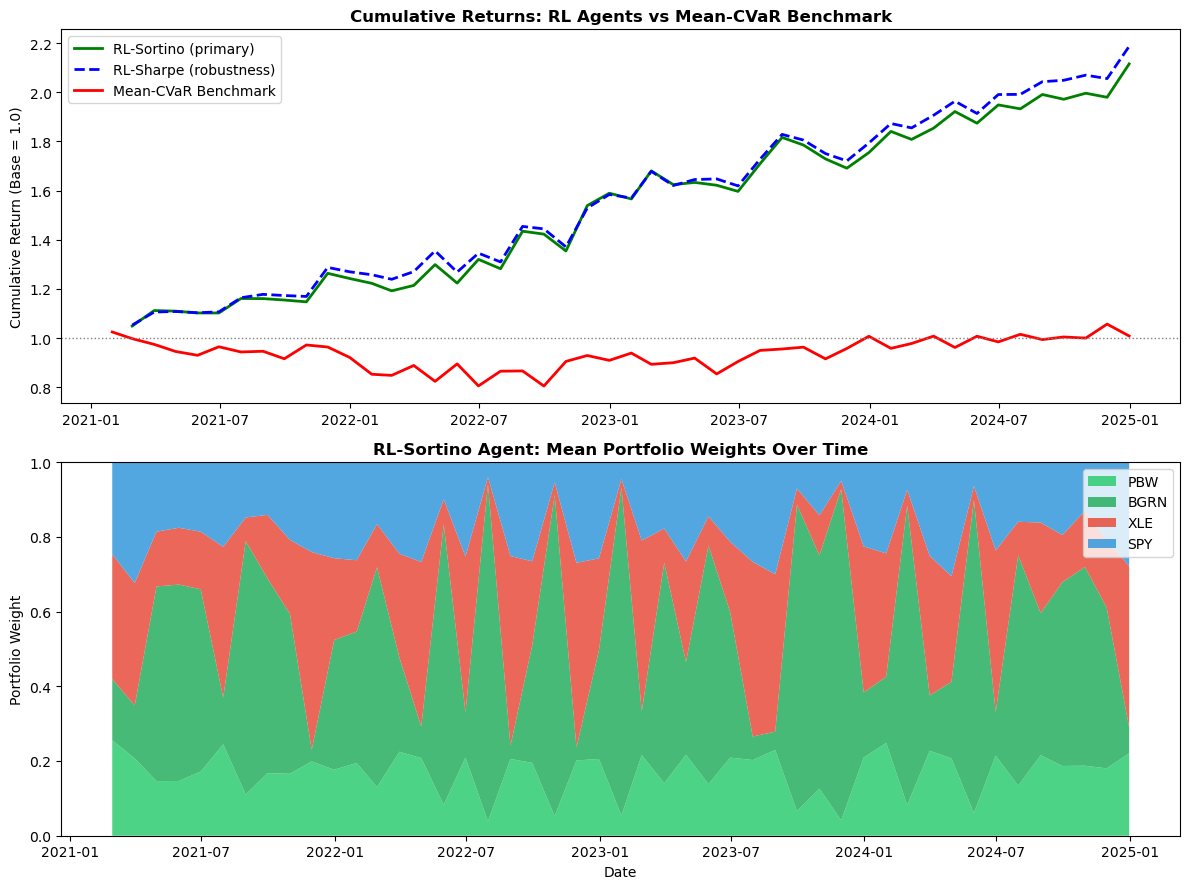

Figure saved: 06_rl_vs_benchmark.png
Results saved to results/ folder.


In [27]:
# ============================================================
# PLOT: CUMULATIVE RETURNS COMPARISON
# ============================================================

# Mean cumulative returns across seeds
def mean_cumulative(returns_list, index):
    aligned = pd.DataFrame(
        {i: r.reindex(index) for i, r in enumerate(returns_list)}
    ).mean(axis=1)
    return (1 + aligned).cumprod()

test_index = test.index[1:]

sort_cum  = mean_cumulative(sortino_returns, test_index)
shar_cum  = mean_cumulative(sharpe_returns,  test_index)

# Load benchmark
bm_returns = pd.read_csv(
    "../results/meancvar_returns.csv", index_col=0, parse_dates=True
).squeeze()
bm_cum = (1 + bm_returns).cumprod()

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

# Plot 1: Cumulative returns comparison
ax1 = axes[0]
ax1.plot(sort_cum.index, sort_cum.values, 
         color="green", linewidth=2, label="RL-Sortino (primary)")
ax1.plot(shar_cum.index, shar_cum.values, 
         color="blue",  linewidth=2, label="RL-Sharpe (robustness)",
         linestyle="--")
ax1.plot(bm_cum.index, bm_cum.values,
         color="red",   linewidth=2, label="Mean-CVaR Benchmark")
ax1.axhline(1.0, color="gray", linestyle=":", linewidth=1)
ax1.set_title("Cumulative Returns: RL Agents vs Mean-CVaR Benchmark",
              fontsize=12, fontweight="bold")
ax1.set_ylabel("Cumulative Return (Base = 1.0)")
ax1.legend()

# Plot 2: Mean portfolio weights (Sortino agent)
mean_weights = pd.concat(sortino_weights).groupby(level=0).mean()
mean_weights = mean_weights.reindex(test_index).fillna(method="ffill")

colors_list = ["#2ecc71", "#27ae60", "#e74c3c", "#3498db"]
ax2 = axes[1]
ax2.stackplot(mean_weights.index,
              [mean_weights[a] for a in ASSETS],
              labels=ASSETS,
              colors=colors_list,
              alpha=0.85)
ax2.set_title("RL-Sortino Agent: Mean Portfolio Weights Over Time",
              fontsize=12, fontweight="bold")
ax2.set_ylabel("Portfolio Weight")
ax2.set_ylim(0, 1)
ax2.set_xlabel("Date")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.savefig("../results/06_rl_vs_benchmark.png", dpi=150)
plt.show()
print("Figure saved: 06_rl_vs_benchmark.png")

# Save results
mean_weights.to_csv("../results/rl_sortino_weights.csv")
pd.concat(sortino_returns, axis=1).mean(axis=1).to_csv(
    "../results/rl_sortino_returns.csv")
pd.concat(sharpe_returns, axis=1).mean(axis=1).to_csv(
    "../results/rl_sharpe_returns.csv")

print("Results saved to results/ folder.")

## Summary

The PPO RL agents are trained and evaluated:
- 10 seeds × 2 reward types = 20 independent agents total
- Results reported as mean ± std across seeds
- Compared against Mean-CVaR benchmark across three periods:
  full sample, low-CPU regime, high-CPU regime

Results saved to results/:
- `rl_sortino_weights.csv` — mean weights across seeds (Sortino)
- `rl_sortino_returns.csv` — mean returns across seeds (Sortino)  
- `rl_sharpe_returns.csv` — mean returns across seeds (Sharpe)
- `06_rl_vs_benchmark.png` — comparison chart

Next: Notebook 5 — Full Results Analysis and Dissertation Tables